In [28]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler

In [29]:
sns.set_theme(style="whitegrid")
plt.rcParams.update({'font.size': 10})

In [30]:
df_raw = pd.read_csv('student_data.csv')
df_clean = df_raw.copy()

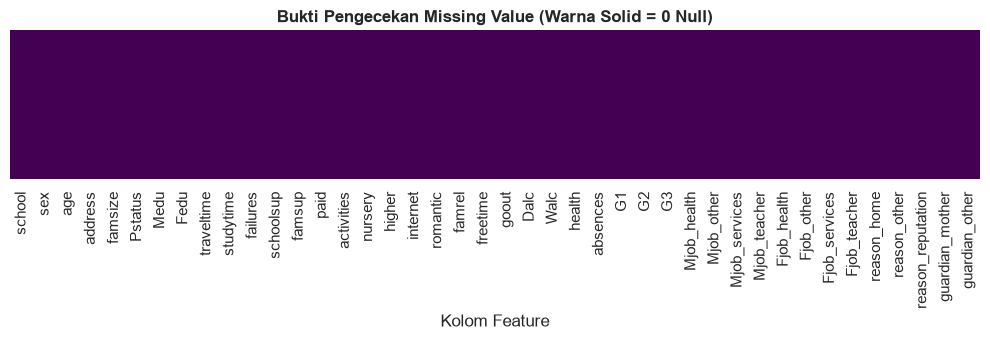

In [41]:
plt.figure(figsize=(10, 3.5))
sns.heatmap(df_clean.isnull(), cbar=False, cmap="viridis", yticklabels=False)
plt.title("Bukti Pengecekan Missing Value (Warna Solid = 0 Null)", fontsize=12, fontweight='bold')
plt.xlabel("Kolom Feature")
plt.tight_layout()
plt.show()

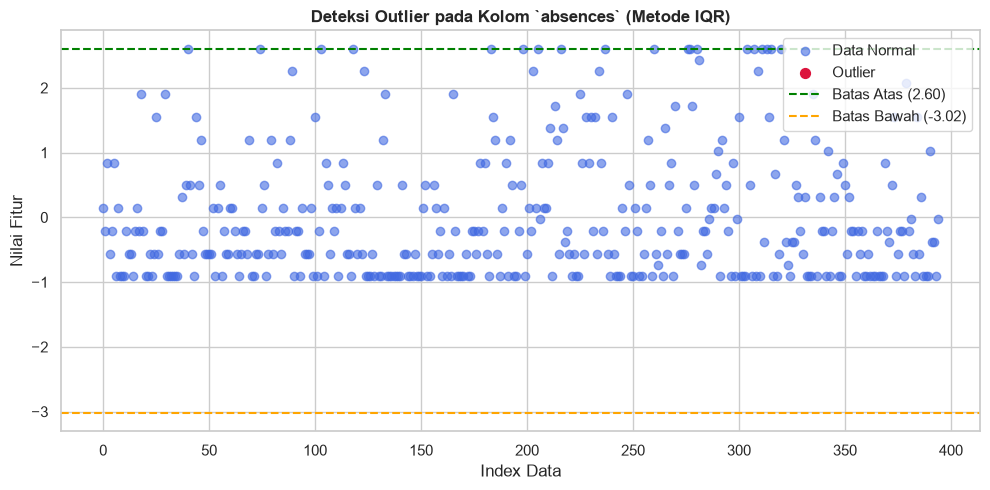

In [52]:
#Tentukan kolom target
target_col = 'absences'

#Hitung Kuartil dan Batas IQR
Q1 = df[target_col].quantile(0.25)
Q3 = df[target_col].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

#Penandaan outlier
df['is_outlier'] = (df[target_col] < lower_bound) | (df[target_col] > upper_bound)

#Visualisasi Scatter Plot
plt.figure(figsize=(10, 5))
plt.scatter(
    df[~df['is_outlier']].index, 
    df[~df['is_outlier']][target_col], 
    color='royalblue', alpha=0.6, label='Data Normal'
)
plt.scatter(
    df[df['is_outlier']].index, 
    df[df['is_outlier']][target_col], 
    color='crimson', s=50, label='Outlier'
)

# Garis ambang batas IQR
plt.axhline(upper_bound, color='green', linestyle='--', linewidth=1.5, label=f'Batas Atas ({upper_bound:.2f})')
plt.axhline(lower_bound, color='orange', linestyle='--', linewidth=1.5, label=f'Batas Bawah ({lower_bound:.2f})')

plt.title(f'Deteksi Outlier pada Kolom `{target_col}` (Metode IQR)', fontsize=12, fontweight='bold')
plt.xlabel('Index Data')
plt.ylabel('Nilai Fitur')
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()

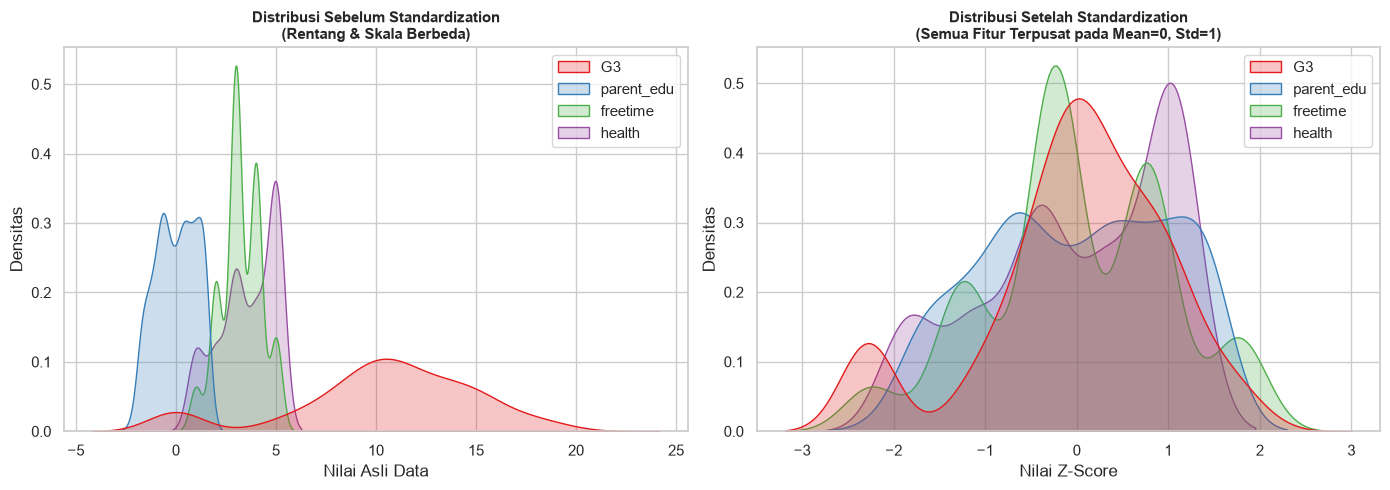

In [58]:
# Pilih beberapa fitur numerik dengan rentang skala berbeda
features = ['G3', 'parent_edu', 'freetime', 'health']
raw_features = df[features].copy()

# Lakukan scaling
scaler = StandardScaler()
scaled_features = pd.DataFrame(scaler.fit_transform(raw_features), columns=features)

# Plot KDE Komparasi
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot Sebelum Scaling
sns.kdeplot(data=raw_features, ax=axes[0], fill=True, common_norm=False, palette='Set1')
axes[0].set_title("Distribusi Sebelum Standardization\n(Rentang & Skala Berbeda)", fontsize=11, fontweight='bold')
axes[0].set_xlabel("Nilai Asli Data")
axes[0].set_ylabel("Densitas")

# Plot Setelah Scaling
sns.kdeplot(data=scaled_features, ax=axes[1], fill=True, common_norm=False, palette='Set1')
axes[1].set_title("Distribusi Setelah Standardization\n(Semua Fitur Terpusat pada Mean=0, Std=1)", fontsize=11, fontweight='bold')
axes[1].set_xlabel("Nilai Z-Score")
axes[1].set_ylabel("Densitas")

plt.tight_layout()
plt.show()

C:\Users\Pongo\AppData\Local\Temp\ipykernel_17024\3541058063.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Mjob_Kategori_Asli', data=df, order=order, ax=axes[0], palette='Blues_r')


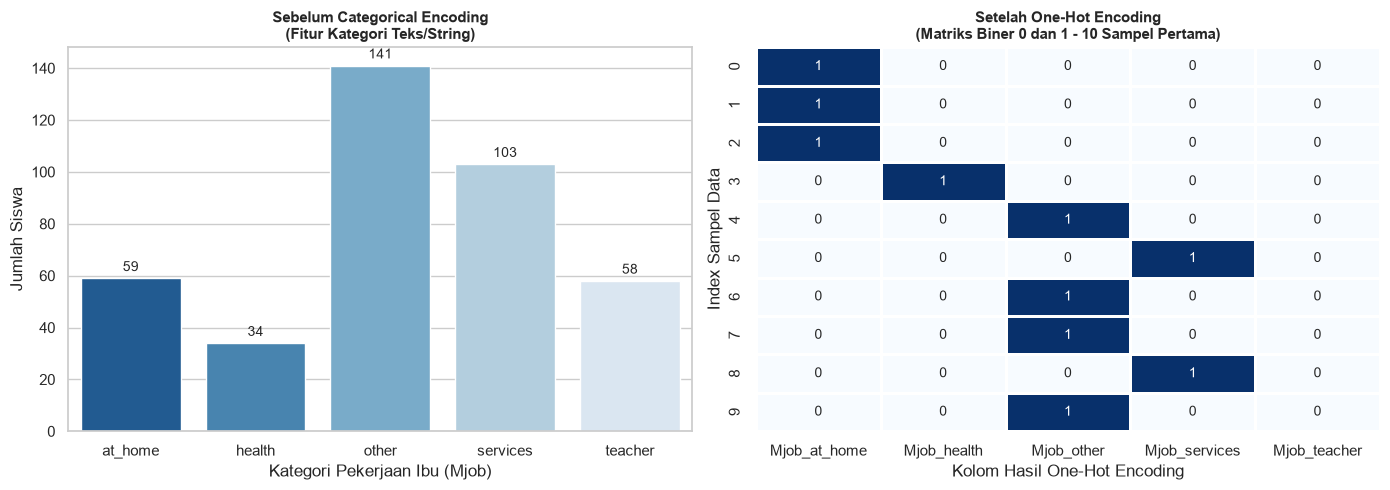

In [59]:
# Rekonstruksi kategori asli 'Mjob' dari kolom One-Hot Encoding
def get_mjob(row):
    if row.get('Mjob_health') == 1: return 'health'
    elif row.get('Mjob_other') == 1: return 'other'
    elif row.get('Mjob_services') == 1: return 'services'
    elif row.get('Mjob_teacher') == 1: return 'teacher'
    else: return 'at_home'

df['Mjob_Kategori_Asli'] = df.apply(get_mjob, axis=1)

# Lakukan One-Hot Encoding
mjob_ohe = pd.get_dummies(df['Mjob_Kategori_Asli'], prefix='Mjob', dtype=int)

# Buat layout visualisasi (1 baris, 2 kolom)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot Kiri: Sebelum Encoding (Frekuensi Kategori String)
order = ['at_home', 'health', 'other', 'services', 'teacher']
sns.countplot(x='Mjob_Kategori_Asli', data=df, order=order, ax=axes[0], palette='Blues_r')
axes[0].set_title('Sebelum Categorical Encoding\n(Fitur Kategori Teks/String)', fontsize=11, fontweight='bold')
axes[0].set_xlabel('Kategori Pekerjaan Ibu (Mjob)')
axes[0].set_ylabel('Jumlah Siswa')

# Menambahkan angka frekuensi di atas setiap bar
for p in axes[0].patches:
    height = p.get_height()
    if height > 0:
        axes[0].annotate(f'{int(height)}', (p.get_x() + p.get_width() / 2., height),
                         ha='center', va='bottom', fontsize=10, xytext=(0, 3), textcoords='offset points')

# Plot Kanan: Setelah Encoding (Heatmap Matriks Biner 0 dan 1)
sns.heatmap(mjob_ohe.head(10), annot=True, cbar=False, cmap='Blues', linewidths=1, ax=axes[1], fmt='d')
axes[1].set_title('Setelah One-Hot Encoding\n(Matriks Biner 0 dan 1 - 10 Sampel Pertama)', fontsize=11, fontweight='bold')
axes[1].set_xlabel('Kolom Hasil One-Hot Encoding')
axes[1].set_ylabel('Index Sampel Data')

plt.tight_layout()
plt.show()